# 01 · Attribution audit: who is over-claiming?

**Question (Q1, part 1):** every ad platform reports how much revenue its ads "drove". Can those
claims be true?

**Simple idea:** if you add up every platform's claim, the total can never be more than what the
company actually sold, because the company also sells to people who saw no ad at all.

Data: sealed stage-1 release, weeks 1–87. Money in ₹ lakh (100 lakh = ₹1 Cr).

In [ ]:
# Colab set-up: run this first (skipped automatically outside Colab)
import sys, os
if "google.colab" in sys.modules:
    REPO_URL = "https://github.com/anvesha2402/prakriti-growth-measurement.git"   # change if your repo differs
    if not os.path.exists("/content/repo"):
        get_ipython().system(f"git clone {REPO_URL} /content/repo")
    os.chdir("/content/repo")
    get_ipython().system("pip install -q 'pymc-marketing==1.1.*' statsmodels")


In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else "src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from common import load, national, CHANNELS, LABEL, COLOR, INK, INK2, NEUTRAL, style, save

style()
w, p = load()
nat = national(w)
actual = nat["revenue_lakh"].sum()
print(f"Weeks: {nat.index.min()}–{nat.index.max()}  |  actual revenue: ₹{actual/100:,.1f} Cr")

Weeks: 1–87  |  actual revenue: ₹165.0 Cr


## 1. Add up the platforms' claims

In [2]:
claims = (p.groupby("channel")
            .agg(spend_lakh=("spend_lakh", "sum"), claimed_lakh=("reported_revenue_lakh", "sum"))
            .reindex(CHANNELS))
claims["claimed_roas"] = claims["claimed_lakh"] / claims["spend_lakh"]
claims["claim_as_share_of_actual_revenue"] = claims["claimed_lakh"] / actual
total_claim = claims["claimed_lakh"].sum()
print(f"Sum of platform claims: ₹{total_claim/100:,.1f} Cr  =  {total_claim/actual:.2f}× actual revenue")
print(f"Total marketing spend:  ₹{claims['spend_lakh'].sum()/100:,.1f} Cr")
out = claims.sort_values("claimed_roas", ascending=False).copy()
out.index = out.index.map(LABEL)
out.round(2)

Sum of platform claims: ₹252.6 Cr  =  1.53× actual revenue
Total marketing spend:  ₹46.4 Cr


,spend_lakh,claimed_lakh,claimed_roas,claim_as_share_of_actual_revenue
channel,,,,
Meta,1192.13,8898.46,7.46,0.54
Quick-commerce ads,1035.38,7531.90,7.27,0.46
Google Search,686.73,3382.50,4.93,0.20
Influencers,457.30,2186.33,4.78,0.13
Trade promotions,548.24,1449.91,2.64,0.09
YouTube,719.81,1810.57,2.52,0.11


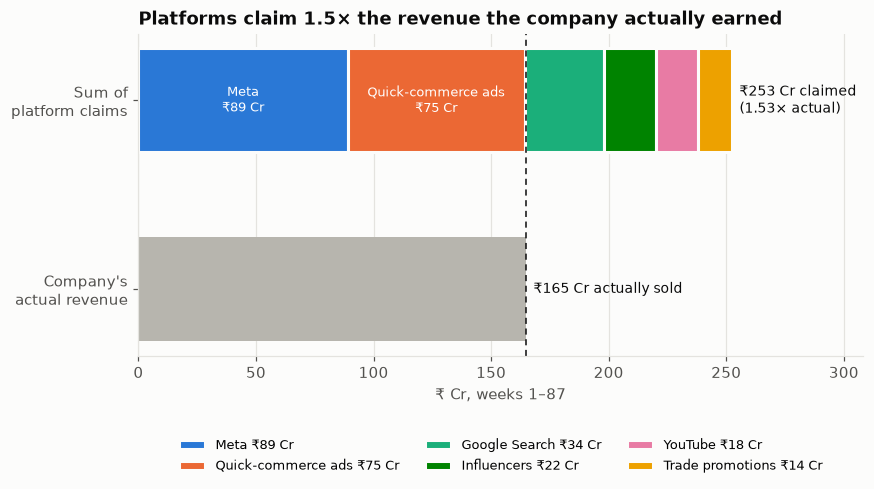

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
left = 0
order = claims.sort_values("claimed_lakh", ascending=False).index
for c in order:
    v = claims.loc[c, "claimed_lakh"] / 100
    ax.barh(1, v, left=left, color=COLOR[c], edgecolor="#fcfcfb", linewidth=2, height=0.55,
            label=f"{LABEL[c]} ₹{v:.0f} Cr")
    if v > 40:
        ax.text(left + v / 2, 1, f"{LABEL[c]}\n₹{v:.0f} Cr", ha="center", va="center", fontsize=8.5, color="white")
    left += v
ax.barh(0, actual / 100, color=NEUTRAL, height=0.55)
ax.axvline(actual / 100, color=INK, lw=1, ls=(0, (4, 3)))
ax.text(actual / 100 + 3, 0, f"₹{actual/100:.0f} Cr actually sold", va="center", color=INK, fontsize=9)
ax.text(left + 3, 1, f"₹{left:.0f} Cr claimed\n({total_claim/actual:.2f}× actual)", va="center", color=INK, fontsize=9)
ax.set_yticks([0, 1], ["Company's\nactual revenue", "Sum of\nplatform claims"])
ax.set_xlabel("₹ Cr, weeks 1–87")
ax.set_xlim(0, left * 1.22)
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, frameon=False, fontsize=8.5)
ax.set_title("Platforms claim 1.5× the revenue the company actually earned")
save(fig, "01_claims_vs_actual"); plt.show()

## 2. The quick-commerce red flag
Quick-commerce ads can only drive quick-commerce sales. Compare their claim with *all*
quick-commerce revenue, including people who search the brand by name or reorder.

In [4]:
qc_rev = nat["rev_quick_commerce_lakh"].sum()
qc_claim = claims.loc["qc_ads", "claimed_lakh"]
print(f"All quick-commerce revenue:           ₹{qc_rev/100:,.1f} Cr")
print(f"Revenue claimed by quick-commerce ads: ₹{qc_claim/100:,.1f} Cr  ({qc_claim/qc_rev:.0%} of all QC sales)")

All quick-commerce revenue:           ₹74.8 Cr
Revenue claimed by quick-commerce ads: ₹75.3 Cr  (101% of all QC sales)


## 3. Trade promotions: the week after
A promotion that only pulls sales forward shows a dip in the following week.

In [5]:
d = nat[["revenue_lakh", "promo_flag"]].copy()
d["trend"] = d["revenue_lakh"].rolling(13, center=True, min_periods=5).median()
d["vs_trend"] = d["revenue_lakh"] / d["trend"] - 1
d["kind"] = np.select([d.promo_flag == 1, d.promo_flag.shift(1).eq(1) & d.promo_flag.eq(0)],
                      ["Promotion week", "Week after a promotion"], "Other weeks")
promo_tbl = d.groupby("kind")["vs_trend"].agg(["mean", "count"]).rename(columns={"mean": "revenue vs 13-week trend"})
print(promo_tbl.round(3))

                        revenue vs 13-week trend  count
kind                                                   
Other weeks                               -0.012     25
Promotion week                             0.022     40
Week after a promotion                    -0.034     22


## 4. So what (for the CFO)
Filled from the numbers above.

In [6]:
s = claims.sort_values("claimed_roas", ascending=False)
print("SO WHAT")
print(f"1. Decision: platform ROAS cannot be used to cut the budget. Platforms claim ₹{total_claim/100:.0f} Cr "
      f"against ₹{actual/100:.0f} Cr actually sold ({total_claim/actual:.2f}×).")
print(f"2. Largest claims: {LABEL[s.index[0]]} (ROAS {s.claimed_roas.iloc[0]:.1f}) and {LABEL[s.index[1]]} "
      f"(ROAS {s.claimed_roas.iloc[1]:.1f}). Quick-commerce ads alone claim {qc_claim/qc_rev:.0%} of all quick-commerce sales.")
print("3. Confidence: certain that claims overstate; how much each channel truly adds needs the MMM (notebook 02B).")

SO WHAT
1. Decision: platform ROAS cannot be used to cut the budget. Platforms claim ₹253 Cr against ₹165 Cr actually sold (1.53×).
2. Largest claims: Meta (ROAS 7.5) and Quick-commerce ads (ROAS 7.3). Quick-commerce ads alone claim 101% of all quick-commerce sales.
3. Confidence: certain that claims overstate; how much each channel truly adds needs the MMM (notebook 02B).
